# 01 — Data Quality Check

Inspect raw recordings before any preprocessing. The goal is to find
problems while sessions can still be repeated.

**Checks performed:**
- File inventory: which sessions/sensors exist vs expected
- Per-file: duration, sampling rate, timestamp monotonicity, gaps, missing values, constant signals
- Visual sanity: accelerometer magnitude plotted per session to catch mislabeled recordings
- Summary action list: REPEAT / WARNING / OK per session

**How to use:**
1. Edit `DATA_ROOT` below if your path differs.
2. `Cell` → `Run All`.
3. Review the **Action List** section at the bottom.
4. Re-record any session marked `REPEAT` or `MISSING` before proceeding.

Expected layout:
```
data/raw/<participant>/<mode>_<day>/
    Accelerometer.csv
    Linear Accelerometer.csv
    Gyroscope.csv
    Barometer.csv          # optional (Babis & Xiomara only)
```

## Imports

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

## Configuration

Adjust `DATA_ROOT` to point at the raw data directory. Everything else describes the expected protocol —
edit only if the protocol genuinely changed.

In [5]:
# --- paths ---
DATA_ROOT = Path('../data/raw')
OUTPUT_DIR = Path('../data/reports')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# --- protocol ---
PARTICIPANTS = ['babis', 'athina', 'xiomara']
MODES = ['stationary', 'walking', 'cycling', 'metro', 'bus', 'tram']
DAYS = ['day1', 'day2', 'day3']

REQUIRED_SENSORS = ['Accelerometer.csv', 'Linear Accelerometer.csv', 'Gyroscope.csv']
OPTIONAL_SENSORS = ['Barometer.csv']

# --- expected quality thresholds ---
TARGET_DURATION_MIN_SECONDS = 6 * 60      # 6 min — anything shorter is flagged
TARGET_DURATION_MAX_SECONDS = 12 * 60     # 12 min — anything longer is flagged
TARGET_SAMPLING_RATE_HZ = 50
MIN_ACCEPTABLE_SAMPLING_RATE = 40
MAX_ACCEPTABLE_GAP_S = 0.5                # gaps larger than this count as 'large'

print(f'DATA_ROOT      : {DATA_ROOT.resolve()}')
print(f'OUTPUT_DIR     : {OUTPUT_DIR.resolve()}')
print(f'Participants   : {PARTICIPANTS}')
print(f'Modes          : {MODES}')
print(f'Days           : {DAYS}')
print(f'Sessions total : {len(PARTICIPANTS) * len(MODES) * len(DAYS)}')

DATA_ROOT      : C:\Projects\this project-transport-mode\data\raw
OUTPUT_DIR     : C:\Projects\this project-transport-mode\data\reports
Participants   : ['babis', 'athina', 'xiomara']
Modes          : ['stationary', 'walking', 'cycling', 'metro', 'bus', 'tram']
Days           : ['day1', 'day2', 'day3']
Sessions total : 54


## Robust CSV loader

Phyphox exports can use different separators (`,` vs `;`) and decimals (`.` vs `,`) depending on the phone's locale.
This loader auto-detects the format so the rest of the notebook doesn't need to care.

In [6]:
def load_phyphox_csv(path):
    """Try common separator/decimal combos. Returns (df, sep, decimal)."""
    last_error = None
    for sep in [',', ';', '\t']:
        for decimal in ['.', ',']:
            if sep == decimal:
                continue
            try:
                df = pd.read_csv(path, sep=sep, decimal=decimal, engine='python')
                if len(df.columns) >= 2 and len(df) > 5:
                    numeric_cols = df.select_dtypes(include=[np.number]).columns
                    if len(numeric_cols) >= 1:
                        return df, sep, decimal
            except Exception as e:
                last_error = e
                continue
    raise ValueError(f'Could not parse {path}: {last_error}')


def find_time_column(df):
    candidates = [c for c in df.columns if 'time' in c.lower() or c.lower().strip() == 't']
    if candidates:
        return candidates[0]
    for col in df.columns:
        if df[col].dtype.kind in 'fi' and df[col].is_monotonic_increasing:
            return col
    return df.columns[0]


def find_value_columns(df, time_col):
    return [c for c in df.columns if c != time_col and df[c].dtype.kind in 'fi']

## 1. File inventory

Walk the directory tree and confirm that every expected session folder exists and contains the required sensor files.

In [7]:
def inventory_sessions(root):
    rows = []
    for p in PARTICIPANTS:
        for m in MODES:
            for d in DAYS:
                folder = root / p / f'{m}_{d}'
                exists = folder.exists()
                required_found = [s for s in REQUIRED_SENSORS if exists and (folder / s).exists()]
                optional_found = [s for s in OPTIONAL_SENSORS if exists and (folder / s).exists()]
                rows.append({
                    'participant': p,
                    'mode': m,
                    'day': d,
                    'session_id': f'{p}_{m}_{d}',
                    'folder_exists': exists,
                    'required_found': len(required_found),
                    'required_total': len(REQUIRED_SENSORS),
                    'optional_found': len(optional_found),
                    'has_all_required': len(required_found) == len(REQUIRED_SENSORS),
                })
    return pd.DataFrame(rows)


inventory = inventory_sessions(DATA_ROOT)
n_total = len(inventory)
n_folder = inventory['folder_exists'].sum()
n_complete = inventory['has_all_required'].sum()

print(f'Expected sessions    : {n_total}')
print(f'Session folders found: {n_folder}')
print(f'Sessions with all required sensors: {n_complete}')
print()

missing = inventory[~inventory['has_all_required']]
if len(missing) == 0:
    print('✓ All required sensor files present in every session folder.')
else:
    print('✗ Sessions with missing required sensors:')
    print(missing[['session_id', 'folder_exists', 'required_found', 'required_total']].to_string(index=False))

Expected sessions    : 54
Session folders found: 54
Sessions with all required sensors: 54

✓ All required sensor files present in every session folder.


## 2. Per-file quality checks

For every sensor CSV that exists, compute:
- duration (s)
- mean sampling rate (Hz) and its instability (std of instantaneous rate)
- timestamp monotonicity and duplicates
- gaps larger than 0.5 s
- missing values in data columns
- constant-column detection (sensor stuck on a value)

In [8]:
def check_sensor_file(path):
    r = {
        'file': path.name,
        'readable': False,
        'n_rows': 0,
        'duration_s': 0.0,
        'rate_hz': 0.0,
        'rate_std': 0.0,
        'monotonic': False,
        'n_duplicates': 0,
        'n_large_gaps': 0,
        'max_gap_s': 0.0,
        'n_missing': 0,
        'n_constant_cols': 0,
        'sep': '',
        'issues': [],
    }
    try:
        df, sep, decimal = load_phyphox_csv(path)
    except Exception as e:
        r['issues'].append(f'unreadable: {str(e)[:80]}')
        return r

    r['readable'] = True
    r['n_rows'] = len(df)
    r['sep'] = sep

    if len(df) < 10:
        r['issues'].append('too few rows')
        return r

    try:
        time_col = find_time_column(df)
        t = pd.to_numeric(df[time_col], errors='coerce').to_numpy()
        value_cols = find_value_columns(df, time_col)
    except Exception as e:
        r['issues'].append(f'column-parse: {str(e)[:60]}')
        return r

    t = t[~np.isnan(t)]
    if len(t) < 10:
        r['issues'].append('time column unparseable')
        return r

    r['duration_s'] = float(t[-1] - t[0])

    dt = np.diff(t)
    dt_pos = dt[dt > 0]
    if len(dt_pos) > 0:
        r['rate_hz'] = float(1.0 / np.mean(dt_pos))
        rates_inst = 1.0 / dt_pos
        r['rate_std'] = float(np.std(rates_inst))

    r['monotonic'] = bool(np.all(dt >= 0))
    if not r['monotonic']:
        r['issues'].append('non-monotonic timestamps')

    r['n_duplicates'] = int(len(t) - len(np.unique(t)))
    if r['n_duplicates'] > 0:
        r['issues'].append(f"{r['n_duplicates']} duplicate timestamps")

    if len(dt) > 0:
        r['n_large_gaps'] = int(np.sum(dt > MAX_ACCEPTABLE_GAP_S))
        r['max_gap_s'] = float(np.max(dt))
        if r['n_large_gaps'] > 0:
            r['issues'].append(f"{r['n_large_gaps']} gaps > {MAX_ACCEPTABLE_GAP_S}s")

    if value_cols:
        numeric_data = df[value_cols].apply(pd.to_numeric, errors='coerce')
        r['n_missing'] = int(numeric_data.isna().sum().sum())
        if r['n_missing'] > 0:
            r['issues'].append(f"{r['n_missing']} missing values")
        n_const = sum(1 for c in value_cols if numeric_data[c].nunique(dropna=True) <= 1)
        r['n_constant_cols'] = n_const
        if n_const > 0:
            r['issues'].append(f"{n_const} constant value columns")

    if r['duration_s'] < TARGET_DURATION_MIN_SECONDS:
        r['issues'].append(f"short duration ({r['duration_s']:.0f}s)")
    elif r['duration_s'] > TARGET_DURATION_MAX_SECONDS:
        r['issues'].append(f"long duration ({r['duration_s']:.0f}s)")

    if 0 < r['rate_hz'] < MIN_ACCEPTABLE_SAMPLING_RATE:
        r['issues'].append(f"low rate ({r['rate_hz']:.1f}Hz)")

    return r

In [9]:
def check_session(participant, mode, day, root=DATA_ROOT):
    folder = root / participant / f'{mode}_{day}'
    session_id = f'{participant}_{mode}_{day}'
    if not folder.exists():
        return {
            'session_id': session_id,
            'participant': participant,
            'mode': mode,
            'day': day,
            'folder_exists': False,
            'files': [],
            'status': 'MISSING',
        }
    file_results = []
    for fname in REQUIRED_SENSORS + OPTIONAL_SENSORS:
        path = folder / fname
        if path.exists():
            r = check_sensor_file(path)
            r['expected'] = fname
            r['required'] = fname in REQUIRED_SENSORS
            file_results.append(r)
        elif fname in REQUIRED_SENSORS:
            file_results.append({
                'file': fname,
                'expected': fname,
                'required': True,
                'readable': False,
                'issues': ['FILE MISSING'],
            })

    # status decision
    critical = False
    has_warnings = False
    for fr in file_results:
        if not fr.get('readable', False) and fr.get('required', False):
            critical = True
        for iss in fr.get('issues', []):
            if 'FILE MISSING' in iss or 'unreadable' in iss or 'constant' in iss or 'non-monotonic' in iss:
                critical = True
            else:
                has_warnings = True

    if critical:
        status = 'REPEAT'
    elif has_warnings:
        status = 'WARNING'
    else:
        status = 'OK'

    return {
        'session_id': session_id,
        'participant': participant,
        'mode': mode,
        'day': day,
        'folder_exists': True,
        'files': file_results,
        'status': status,
    }


all_sessions = []
for p in PARTICIPANTS:
    for m in MODES:
        for d in DAYS:
            all_sessions.append(check_session(p, m, d))

print(f'Ran QC on {len(all_sessions)} sessions.')
print()
status_counts = pd.Series([s['status'] for s in all_sessions]).value_counts()
print('Status breakdown:')
for k, v in status_counts.items():
    print(f'  {k:8s}: {v}')

Ran QC on 54 sessions.

Status breakdown:
  OK      : 8


## 3. Per-file detail table

One row per sensor file. Easier to scan for outliers (durations, rates).

In [10]:
detail_rows = []
for s in all_sessions:
    for f in s.get('files', []):
        detail_rows.append({
            'session': s['session_id'],
            'file': f.get('file', '?'),
            'required': f.get('required', False),
            'readable': f.get('readable', False),
            'rows': f.get('n_rows', 0),
            'duration_s': round(f.get('duration_s', 0), 1),
            'rate_hz': round(f.get('rate_hz', 0), 1),
            'rate_std': round(f.get('rate_std', 0), 2),
            'monotonic': f.get('monotonic', False),
            'gaps_>0.5s': f.get('n_large_gaps', 0),
            'max_gap_s': round(f.get('max_gap_s', 0), 2),
            'missing': f.get('n_missing', 0),
            'const_cols': f.get('n_constant_cols', 0),
            'issues': '; '.join(f.get('issues', [])) or '—',
        })

detail_df = pd.DataFrame(detail_rows)
detail_df

,session,file,required,readable,rows,duration_s,rate_hz,rate_std,monotonic,gaps_>0.5s,max_gap_s,missing,const_cols,issues
0,babis_stationary_day1,Accelerometer.csv,True,True,72616,724.0,100.3,0.03,True,0,0.01,0,0,long duration (724s)
1,babis_stationary_day1,Linear Accelerometer.csv,True,True,72616,724.0,100.3,0.03,True,0,0.01,0,0,long duration (724s)
2,babis_stationary_day1,Gyroscope.csv,True,True,72616,724.0,100.3,0.03,True,0,0.01,0,0,long duration (724s)
3,babis_stationary_day1,Barometer.csv,False,True,681,721.6,0.9,0.16,True,679,1.06,0,0,679 gaps > 0.5s; long duration (722s); low rat...
4,babis_stationary_day2,Accelerometer.csv,True,True,72811,725.9,100.3,0.03,True,0,0.01,0,0,long duration (726s)
5,babis_stationary_day2,Linear Accelerometer.csv,True,True,72811,725.9,100.3,0.03,True,0,0.01,0,0,long duration (726s)
6,babis_stationary_day2,Gyroscope.csv,True,True,72811,725.9,100.3,0.03,True,0,0.01,0,0,long duration (726s)
7,babis_stationary_day2,Barometer.csv,False,True,683,723.6,0.9,0.16,True,681,1.06,0,0,681 gaps > 0.5s; long duration (724s); low rat...
8,babis_stationary_day3,Accelerometer.csv,True,True,72655,724.3,100.3,0.03,True,0,0.01,0,0,long duration (724s)
9,babis_stationary_day3,Linear Accelerometer.csv,True,True,72655,724.3,100.3,0.03,True,0,0.01,0,0,long duration (724s)


## 4. Distributions of durations and sampling rates

Visual outlier detection. Most files should cluster around the target.

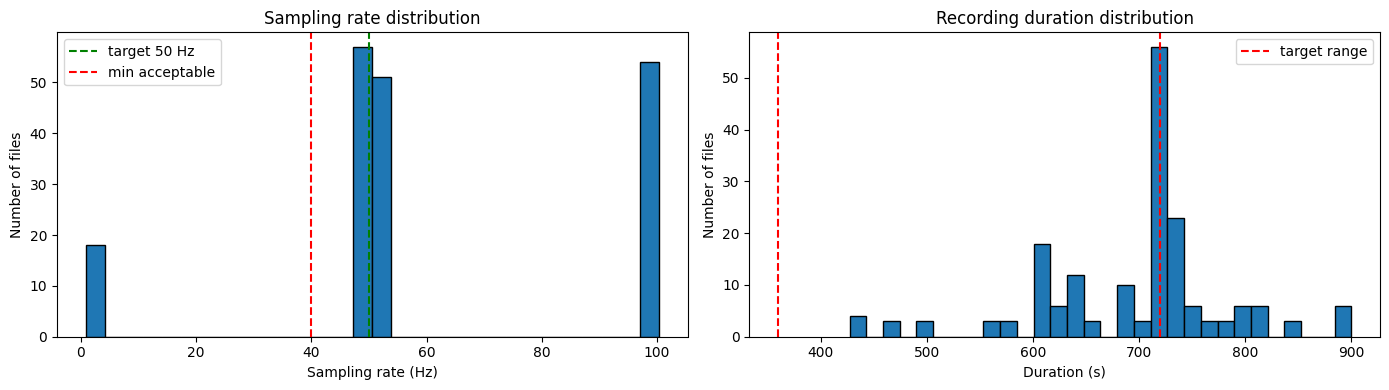

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

readable_df = detail_df[detail_df['readable']]

ax = axes[0]
rates = readable_df[readable_df['rate_hz'] > 0]['rate_hz']
if len(rates) > 0:
    ax.hist(rates, bins=30, edgecolor='black')
ax.axvline(TARGET_SAMPLING_RATE_HZ, color='green', linestyle='--', label=f'target {TARGET_SAMPLING_RATE_HZ} Hz')
ax.axvline(MIN_ACCEPTABLE_SAMPLING_RATE, color='red', linestyle='--', label='min acceptable')
ax.set_xlabel('Sampling rate (Hz)')
ax.set_ylabel('Number of files')
ax.set_title('Sampling rate distribution')
ax.legend()

ax = axes[1]
durations = readable_df['duration_s']
if len(durations) > 0:
    ax.hist(durations, bins=30, edgecolor='black')
ax.axvline(TARGET_DURATION_MIN_SECONDS, color='red', linestyle='--', label='target range')
ax.axvline(TARGET_DURATION_MAX_SECONDS, color='red', linestyle='--')
ax.set_xlabel('Duration (s)')
ax.set_ylabel('Number of files')
ax.set_title('Recording duration distribution')
ax.legend()

plt.tight_layout()
plt.show()

## 5. Sampling rate by participant × sensor

Pivot view to spot device-specific or sensor-specific rate issues.

In [12]:
if len(readable_df) > 0:
    rate_pivot = readable_df.assign(
        participant=lambda d: d['session'].str.split('_').str[0],
        sensor=lambda d: d['file'].str.replace('.csv', '', regex=False),
    ).pivot_table(index='participant', columns='sensor', values='rate_hz', aggfunc='mean').round(1)
    print('Mean sampling rate (Hz) by participant × sensor:')
    print(rate_pivot.to_string())
else:
    print('No readable files to summarise.')

Mean sampling rate (Hz) by participant × sensor:
sensor       Accelerometer  Barometer  Gyroscope  Linear Accelerometer
participant                                                           
athina                49.8        NaN       50.0                  49.9
babis                100.3        0.9      100.3                 100.3
xiomara               52.2        NaN       52.9                  53.0


## 6. Signal sanity check

Accelerometer magnitude plotted per session. Rows = participants, columns = modes, colors = day1 vs day2.

Visual scan for mislabels:
- **stationary**: should be near-flat, very low variance
- **walking, cycling**: clear periodic patterns
- **metro, bus, tram**: lower-frequency variation with occasional spikes (stops/starts)

If a panel doesn't match its label, the recording is probably mislabeled or wrong-mode.

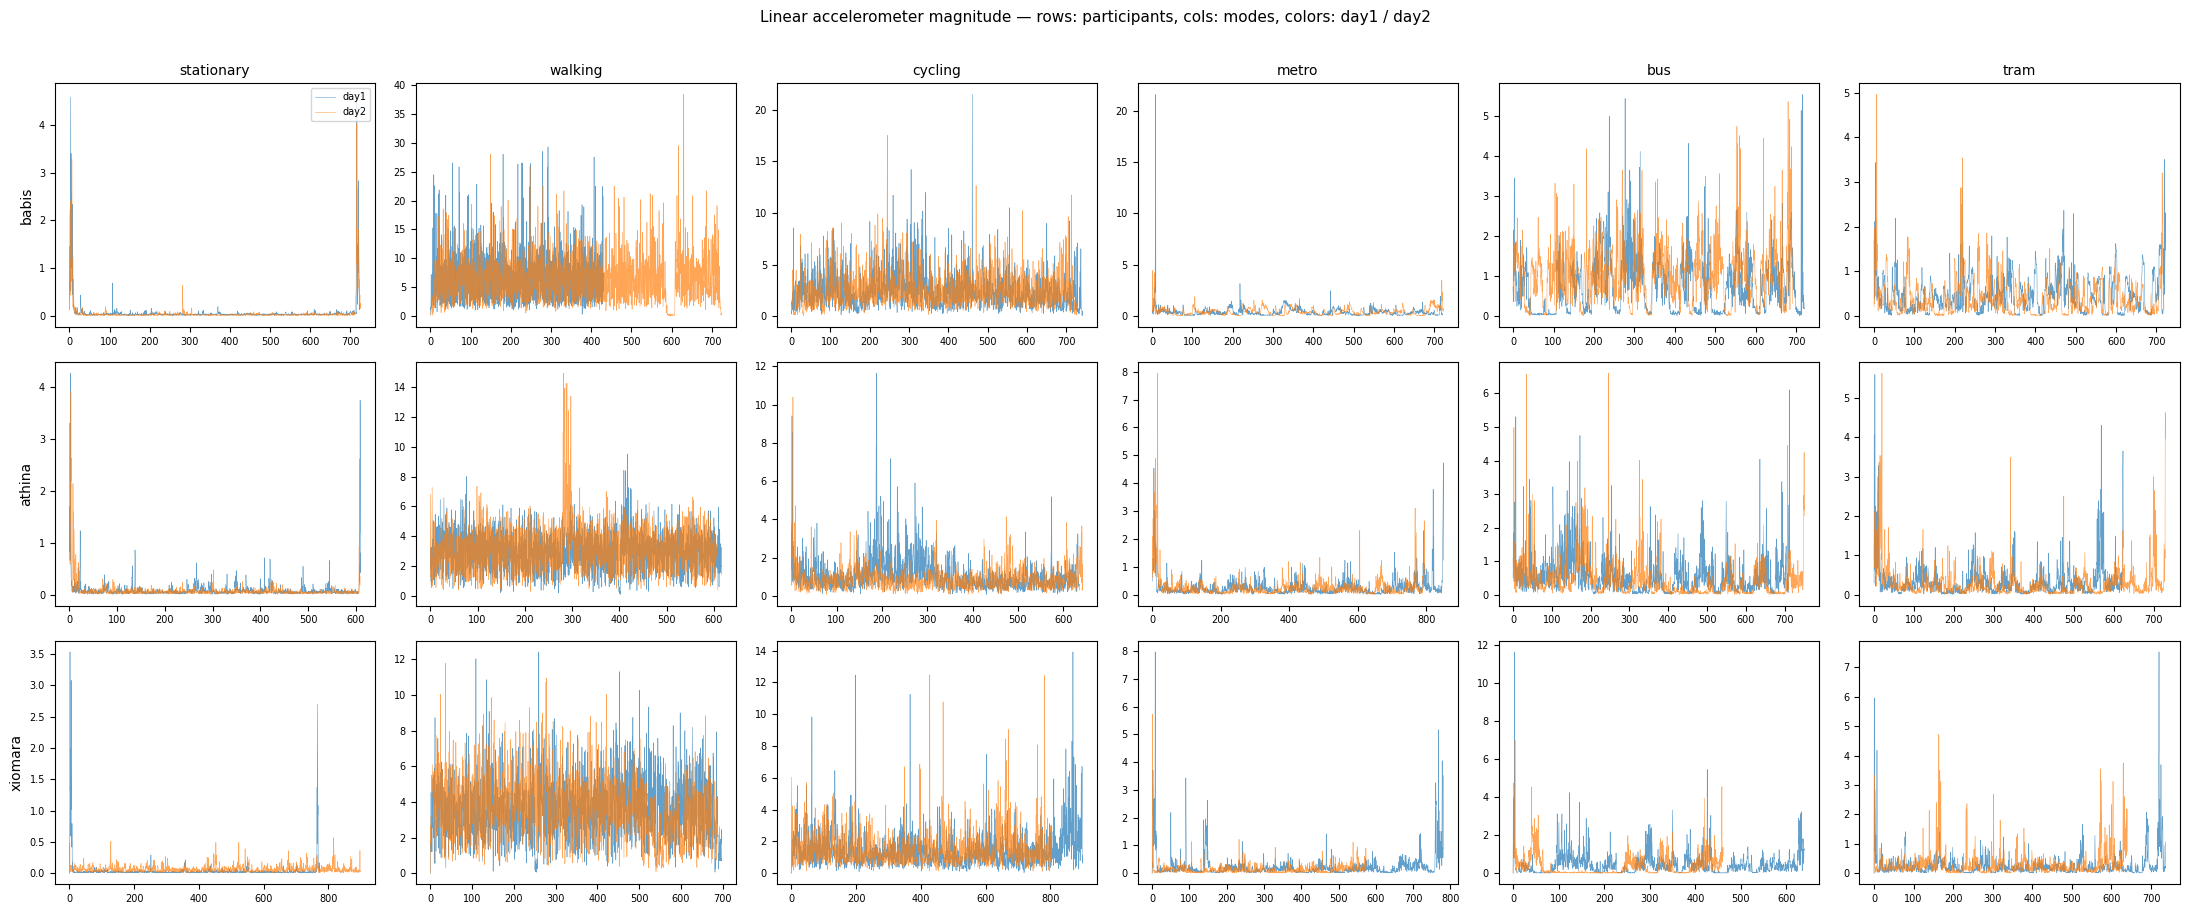

In [13]:
def acc_magnitude_for_session(participant, mode, day, root=DATA_ROOT):
    folder = root / participant / f'{mode}_{day}'
    # prefer Linear Accelerometer (gravity removed) for cleaner signal
    for fname in ['Linear Accelerometer.csv', 'Accelerometer.csv']:
        path = folder / fname
        if path.exists():
            try:
                df, _, _ = load_phyphox_csv(path)
                time_col = find_time_column(df)
                value_cols = find_value_columns(df, time_col)
                if len(value_cols) < 3:
                    continue
                t = pd.to_numeric(df[time_col], errors='coerce').to_numpy()
                xyz = df[value_cols[:3]].apply(pd.to_numeric, errors='coerce').to_numpy()
                mask = ~np.isnan(t) & ~np.isnan(xyz).any(axis=1)
                t, xyz = t[mask], xyz[mask]
                if len(t) < 10:
                    continue
                t = t - t[0]
                mag = np.sqrt(np.sum(xyz**2, axis=1))
                return t, mag
            except Exception:
                continue
    return None, None


fig, axes = plt.subplots(len(PARTICIPANTS), len(MODES), figsize=(22, 9), sharex=False)
if len(PARTICIPANTS) == 1:
    axes = np.array([axes])

for i, p in enumerate(PARTICIPANTS):
    for j, m in enumerate(MODES):
        ax = axes[i, j]
        any_plotted = False
        for day, color in zip(DAYS, ['tab:blue', 'tab:orange']):
            t, mag = acc_magnitude_for_session(p, m, day)
            if t is not None:
                step = max(1, len(t) // 1500)
                ax.plot(t[::step], mag[::step], linewidth=0.4, alpha=0.7, color=color, label=day)
                any_plotted = True
        if not any_plotted:
            ax.text(0.5, 0.5, 'no data', ha='center', va='center',
                    transform=ax.transAxes, color='red')
        if i == 0:
            ax.set_title(m, fontsize=10)
        if j == 0:
            ax.set_ylabel(p, fontsize=10)
        ax.tick_params(labelsize=7)

# legend on first panel
handles, labels = axes[0, 0].get_legend_handles_labels()
if handles:
    axes[0, 0].legend(fontsize=7, loc='upper right')

plt.suptitle('Linear accelerometer magnitude — rows: participants, cols: modes, colors: day1 / day2',
             y=1.01, fontsize=11)
plt.tight_layout()
plt.show()

## 7. Quick label-sanity numbers

Standard deviation of accelerometer magnitude per session. This is a fast objective sanity check:
stationary should have the lowest std, walking/cycling clearly higher, vehicular modes intermediate.
Anything obviously inconsistent (e.g. a 'stationary' session with very high std) is a likely mislabel.

In [14]:
std_rows = []
for p in PARTICIPANTS:
    for m in MODES:
        for d in DAYS:
            t, mag = acc_magnitude_for_session(p, m, d)
            if mag is not None and len(mag) > 10:
                std_rows.append({
                    'participant': p,
                    'mode': m,
                    'day': d,
                    'session_id': f'{p}_{m}_{d}',
                    'mag_std': round(float(np.std(mag)), 3),
                    'mag_mean': round(float(np.mean(mag)), 3),
                })

std_df = pd.DataFrame(std_rows)
if len(std_df) > 0:
    print('Mean acceleration magnitude std by mode (averaged across participants and days):')
    print(std_df.groupby('mode')['mag_std'].agg(['mean', 'std', 'count']).round(3).to_string())
    print()
    print('Expected ordering: stationary < (vehicular: metro/bus/tram) < walking < cycling.')
    print('If your numbers deviate strongly, inspect those sessions in section 6 above.')
else:
    print('Could not compute magnitude statistics — no readable accelerometer data.')

Mean acceleration magnitude std by mode (averaged across participants and days):
             mean    std  count
mode                           
bus         0.664  0.076      9
cycling     1.230  0.389      9
metro       0.349  0.113      9
stationary  0.200  0.062      9
tram        0.424  0.088      9
walking     2.349  1.134      9

Expected ordering: stationary < (vehicular: metro/bus/tram) < walking < cycling.
If your numbers deviate strongly, inspect those sessions in section 6 above.


In [16]:
walk = std_df[std_df['mode'] == 'walking']
print(walk.groupby('participant')[['mag_mean', 'mag_std']].agg(['mean', 'std']).round(3))

            mag_mean        mag_std       
                mean    std    mean    std
participant                               
athina         3.381  0.436   1.477  0.153
babis          6.443  0.515   3.820  0.431
xiomara        3.258  0.656   1.749  0.086


## 8. Action list

**This is the section to act on.** Sessions are grouped by required action:
- **REPEAT / MISSING**: re-record before continuing
- **WARNING**: review the issues, decide whether they're tolerable
- **OK**: usable as-is

In [17]:
status_df = pd.DataFrame([
    {
        'session_id': s['session_id'],
        'participant': s['participant'],
        'mode': s['mode'],
        'day': s['day'],
        'status': s['status'],
        'issues': '; '.join(sorted(set(
            iss for f in s.get('files', []) for iss in f.get('issues', [])
        ))) or '—',
    }
    for s in all_sessions
])

order = {'REPEAT': 0, 'MISSING': 1, 'WARNING': 2, 'OK': 3}
status_df['_sort'] = status_df['status'].map(order)
status_df = status_df.sort_values(['_sort', 'session_id']).drop(columns='_sort').reset_index(drop=True)

print('=' * 70)
print('ACTION REQUIRED (re-record before proceeding)')
print('=' * 70)
critical = status_df[status_df['status'].isin(['REPEAT', 'MISSING'])]
if len(critical) == 0:
    print('None — no critical issues found.')
else:
    print(critical.to_string(index=False))

print()
print('=' * 70)
print('WARNINGS (review, may not need repeat)')
print('=' * 70)
warns = status_df[status_df['status'] == 'WARNING']
if len(warns) == 0:
    print('None.')
else:
    print(warns.to_string(index=False))

print()
print('=' * 70)
n_ok = (status_df['status'] == 'OK').sum()
print(f'OK SESSIONS: {n_ok} of {len(status_df)}')
print('=' * 70)

ACTION REQUIRED (re-record before proceeding)
None — no critical issues found.

WARNINGS (review, may not need repeat)
             session_id participant       mode  day  status                                                                                             issues
        athina_bus_day1      athina        bus day1 WARNING                                                  199 duplicate timestamps; 91 duplicate timestamps
        athina_bus_day2      athina        bus day2 WARNING                             25 duplicate timestamps; 28 duplicate timestamps; long duration (752s)
        athina_bus_day3      athina        bus day3 WARNING                            212 duplicate timestamps; 85 duplicate timestamps; long duration (808s)
    athina_cycling_day1      athina    cycling day1 WARNING                                                  181 duplicate timestamps; 79 duplicate timestamps
    athina_cycling_day2      athina    cycling day2 WARNING                           

## 9. Save reports

Persisted to `data/reports/` so other notebooks and the report can reference them without re-running QC.

In [18]:
status_df.to_csv(OUTPUT_DIR / 'data_quality_summary.csv', index=False)
detail_df.to_csv(OUTPUT_DIR / 'data_quality_per_file.csv', index=False)
if len(std_df) > 0:
    std_df.to_csv(OUTPUT_DIR / 'data_quality_magnitude_stats.csv', index=False)

print('Saved:')
for fname in ['data_quality_summary.csv', 'data_quality_per_file.csv', 'data_quality_magnitude_stats.csv']:
    fpath = OUTPUT_DIR / fname
    if fpath.exists():
        print(f'  {fpath}')

Saved:
  ..\data\reports\data_quality_summary.csv
  ..\data\reports\data_quality_per_file.csv
  ..\data\reports\data_quality_magnitude_stats.csv


## Next steps

Once all sessions are `OK` or you've accepted the `WARNING` items:

1. Move on to `02_preprocessing_and_merging.ipynb` — resampling, trimming, gap interpolation, windowing.
2. Keep this notebook in the repo as a reproducibility artifact. Re-run it whenever new sessions are added.

**Critical rule from the project plan (section 11):**
> A noisy sensor can sometimes be cleaned, but a wrong label cannot be fixed.

If the section 7 magnitude-std table or the section 6 visual grid suggests a mislabel,
treat it as REPEAT regardless of what the file-level checks say.